# Switching Linear Dynamical System

## Switching Linear Dynamical System Demo

_Switching Linear Dynamical Systems_ (SLDS) provide a natural way of combining Linear Dynamical Systems with Hidden Markov Models. They allow us to approximate a system that has globally non-linear dynamics by a series of linear systems. A good reference for these types of systems is ["Variational Inference for State Space models"](https://www.cs.toronto.edu/~hinton/absps/switch.pdf) by Ghahramani and Hinton. 

An SLDS comprises $K$ discrete hidden states, which evolve according to a Markov chain. We'll call the hidden state $z$, and use the notation $z_t = k$ to mean that the system is in state $k$ at time $t$. The Markov chain for the hidden state is specified by a state-transition matrix $Q$, where $Q_{ij} = P(z_t = j \mid z_{t-1} = i)$.

### Generative Model for SLDS
The generative model for an SLDS combines an HMM with a set of linear dynamical systems as follows. In addition to the discrete state, we have a continuous latent state $x_t \in \mathbb{R}^D$ and an observation $y_t \in \mathbb{R}^N$. Each discrete state $\{1,\ldots,K
\}$ is associated with a different dynamics matrix $A_k$ and a different measurement matrix $C_k$. Formally, we generate data from an SLDS as follows:

1. **Discrete State Update**. At each time step, sample a new discrete state $z_t \mid z_{t-1}$ with probabilities given by a Markov chain.

2. **Continuous State Update**. Update the state using the dynamics matrix corresponding to the new discrete state:

   $$
   x_t = A_k x_{t-1} + V_k u_{t} + b_k + w_t
   $$
   $A_k$ is the dynamics matrix corresponding to discrete state $k$. $u_t$ is the input vector (specified by the user, not inferred by Dynamax) and $V_k$ is the corresponding control matrix. The vector $b$ is an offset vector, which can drive the dynamics in a particular direction. 
   The term $w_t$ is a noise term, which perturbs the dynamics. 
   Most commonly these are modeled as zero-mean multivariate Gaussians, which is what Dynamax's `GaussianSLDS` assumes.

3. **Emission**. We now make an observation of the state, according to the specified observation model. In the general case, the state controls the observation via a Generalized Linear Model:

   $$
   y_t \sim \mathcal{P}(\eta(C_k x_t + d_k + F_k u_t + v_t))
   $$
   $\mathcal{P}$ is a probability distribution. The inner arguments form an affine measurement of the state, which is then passed through the inverse link function $\eta(\cdot)$.
   In this case, $C_k$ is the measurement matrix corresponding to discrete state $k$, $d_k$ is an offset or bias term corresponding to discrete state $k$, $F_k$ is called the feedthrough matrix or passthrough matrix (it passes the input directly to the emission). In the Gaussian case, the emission can simply be written as $y_t = C_k x_t + d_k + F_k u_t + v_t$ where $v_t$ is a Gaussian r.v. `GaussianSLDS` implements this Gaussian case.
   

## 1. Setup
We import Dynamax as well as a few other utilities for plotting.

In [1]:
%%capture
try:
    import dynamax
except ModuleNotFoundError:
    print('installing dynamax')
    %pip install -q dynamax[notebooks]
    import dynamax

In [2]:
import jax
import jax.numpy as jnp
import jax.random as jr
import numpy as np
key = jr.PRNGKey(4)

import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

%matplotlib inline

import seaborn as sns

sns.set_style("white")
sns.set_context("talk")

color_names = ["windows blue",
               "red",
               "amber",
               "faded green",
               "dusty purple",
               "orange",
               "clay",
               "pink",
               "greyish",
               "mint",
               "cyan",
               "steel blue",
               "forest green",
               "pastel purple",
               "salmon",
               "dark brown"]

colors = sns.xkcd_palette(color_names)
cmap = ListedColormap(colors)

from dynamax.slds import GaussianSLDS
from dynamax.utils.utils import random_rotation, find_permutation

## 2. Creating an SLDS and Sampling
Below, we set some parameters for our SLDS: 5 discrete states, latent state of dimension 2, emissions of dimensions 10. We'll be sampling for 100 time bins for the purpose of visualizing the output of our SLDS.

We then create an SLDS object and draw its parameters:
```python
true_slds = GaussianSLDS(n_disc_states, latent_dim, emissions_dim)
true_params, _ = true_slds.initialize(key, ...)
```
`GaussianSLDS` has Gaussian dynamics and Gaussian emissions. Below we draw the parameters ourselves: an orthogonal measurement matrix $C$, standard normal biases, random noise covariances and a sticky transition matrix. Because an orthogonal matrix is full-rank, this means that our system is fully observable. In other words, the emissions model does not lose information about the state.

The syntax for sampling from an SLDS is the same as for an LDS:
```python
states_z, states_x, emissions = true_slds.sample(true_params, key, time_bins)
```
The sample function for SLDS returns a tuple of (discrete states, continuous states, observations).


In [3]:
# Set the parameters of the SLDS
time_bins = 100    # number of time bins
n_disc_states = 5       # number of discrete states
latent_dim = 2       # number of latent dimensions
emissions_dim = 10      # number of observed dimensions

In [4]:
# Make an SLDS with the true parameters
true_slds = GaussianSLDS(n_disc_states, latent_dim, emissions_dim)

# Draw the parameters: an orthogonal measurement matrix, standard normal biases, random noise covariances and a sticky transition matrix
key, k_init, k_P, k_b, k_Q, k_C, k_d, k_R = jr.split(key, 8)
Ps = .95 * jnp.eye(n_disc_states) + .05 * jr.uniform(k_P, (n_disc_states, n_disc_states))
sqrt_Sigmas = jr.normal(k_Q, (n_disc_states, latent_dim, latent_dim))
true_params, _ = true_slds.initialize(
    k_init,
    initial_params=dict(initial_probs=jnp.ones(n_disc_states) / n_disc_states),
    transition_params=dict(transition_matrix=Ps / Ps.sum(axis=1, keepdims=True)),
    dynamics_params=dict(biases=jr.normal(k_b, (n_disc_states, latent_dim)),
                         covs=sqrt_Sigmas @ jnp.swapaxes(sqrt_Sigmas, -1, -2)),
    emission_params=dict(weights=jnp.linalg.svd(jr.normal(k_C, (1, emissions_dim, latent_dim)), full_matrices=False)[0],
                         biases=jr.normal(k_d, (1, emissions_dim)),
                         covs=jnp.exp(-1 + jr.normal(k_R, (1, emissions_dim)))))

key, *subkeys = jr.split(key, n_disc_states + 1)
As = true_params.dynamics.weights
for k in range(n_disc_states):
    As = As.at[k].set(.95 * random_rotation(subkeys[k], latent_dim, theta=(k+1) * np.pi/20))
true_params = true_params._replace(dynamics=true_params.dynamics._replace(weights=As))

key, k_sample = jr.split(key)
states_z, states_x, emissions = true_slds.sample(true_params, k_sample, time_bins)

### 2.1 Visualize the Latent States
Below, we visualize the 2-dimensional trajectory of the continuous latent state $x_t$. The different colors correspond to different values of the discrete state variable $z_t$. We can see how the different colors correspond to different dynamics on the latent state.

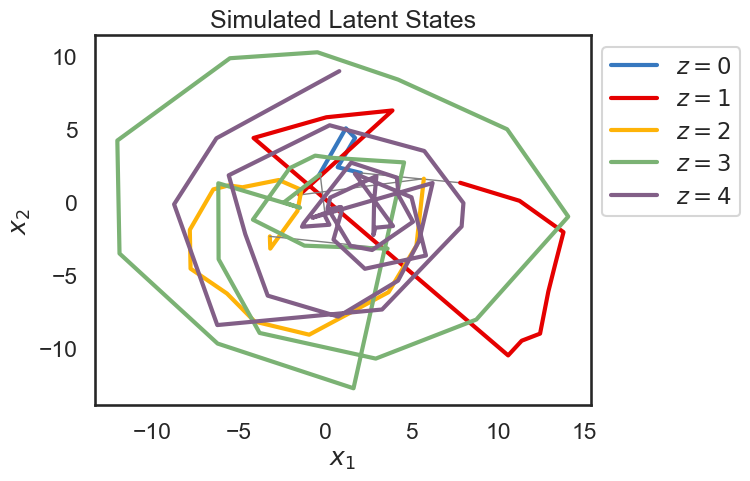

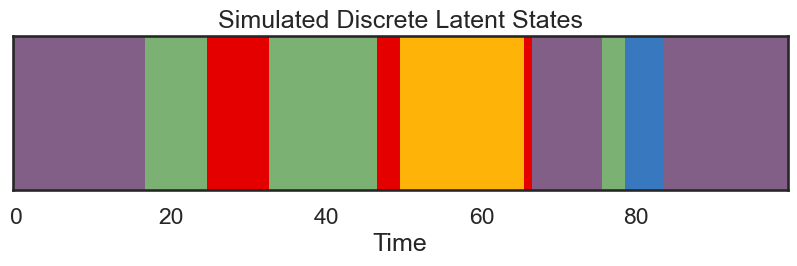

In [5]:
for k in range(n_disc_states):
    curr_states = states_x[states_z == k]
    plt.plot(curr_states[:,0],
             curr_states[:,1],
             '-',
             color=colors[k],
             lw=3,
             label="$z=%i$" % k)
    
    # Draw lines connecting the latent state between discrete state transitions,
    # so they don't show up as broken lines.
    next_states = states_x[states_z == k+1]
    if len(next_states) > 0 and len(curr_states) > 0:
        plt.plot((curr_states[-1,0], next_states[0,0]),
                 (curr_states[-1,1], next_states[0,1]),
                 '-',
                 color='gray',
                 lw=1)

plt.xlabel("$x_1$")
plt.ylabel("$x_2$")
plt.title("Simulated Latent States")
plt.legend(bbox_to_anchor=(1.0,1.0))
plt.show()

plt.figure(figsize=(10,2))
cmap_limited = ListedColormap(colors[0:n_disc_states])
plt.imshow(states_z[None,:],  aspect="auto", cmap=cmap_limited)
plt.title("Simulated Discrete Latent States")
plt.yticks([])
plt.xlabel("Time")
plt.show()

### 2.2 Visualize the Emissions
Below, we visualize the 10-dimensional emissions from our SLDS.

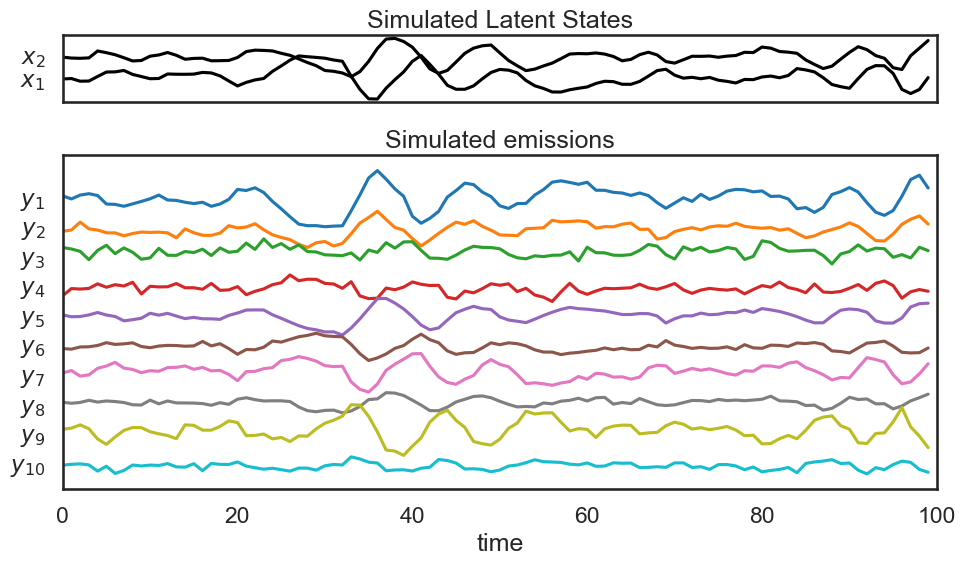

In [6]:
plt.figure(figsize=(10, 6))
gs = plt.GridSpec(2, 1, height_ratios=(1, emissions_dim/latent_dim))

# Plot the continuous latent states
lim = abs(states_x).max()
plt.subplot(gs[0])
for d in range(latent_dim):
    plt.plot(states_x[:, d] + lim * d, '-k')
plt.yticks(np.arange(latent_dim) * lim, ["$x_{}$".format(d+1) for d in range(latent_dim)])
plt.xticks([])
plt.xlim(0, time_bins)
plt.title("Simulated Latent States")

lim = abs(emissions).max()
plt.subplot(gs[1])
for n in range(emissions_dim):
    plt.plot(emissions[:, n] - lim * n, '-')
plt.yticks(-np.arange(emissions_dim) * lim, ["$y_{{ {} }}$".format(n+1) for n in range(emissions_dim)])
plt.xlabel("time")
plt.xlim(0, time_bins)

plt.title("Simulated emissions")
plt.tight_layout()

## 3. Fit an SLDS From Data
Dynamax provides the capability to learn the parameters of an SLDS from data. In the above cells, we sampled from 100 time-steps in order to visualize the state trajectory.

In order to learn an SLDS, we'll need more data, so we start by sampling for a longer period. In the following cells, we'll treat our observations as a dataset, and demonstrate how to learn an SLDS using Dynamax.

In [7]:
# Sample again, for more time-bins
time_bins = 1000
key, k_sample = jr.split(key)
states_z, states_x, emissions = true_slds.sample(true_params, k_sample, time_bins)
data = emissions

### 3.1 Fitting Methods

**Important Note:**  
 <span style="font-size:larger;">
Understanding the following section is not necessary to use Dynamax! _`fit_em` runs Laplace-EM with the structured mean-field posterior._
</span>

**Parameter Learning for SLDS**  
Parameter learning in an SLDS requires approximate methods. Dynamax implements Laplace-Approximate EM. We don't have the space to describe the method in detail here, but the Laplace Approximation is described in several sources, and a good reference for the context of state-space models is ["Estimating State and Parameters in state-space models of Spike Trains,"](https://pdfs.semanticscholar.org/a71e/bf112cabd47cc67284dc8c12ab7644195d60.pdf) a book chapter by Macke et al.

**Approximate Posterior Distributions**
When using approximate methods, we must choose the form of the distribution we use to approximate the posterior. Dynamax uses the structured mean-field posterior, which assumes that the joint distribution over the continuous and discrete latent states factors as follows. If $q(z,x \mid y)$ is the joint posterior of the discrete and continuous states given the data, we use the approximation $q(z,x \mid y) \approx q(z \mid y)q(x \mid y)$, where $q(z \mid y)$ is the posterior for a Markov chain.

**Calling `fit_em` in Dynamax**  
Dynamax's HMMs, linear Gaussian SSMs and SLDSs share the same general syntax for fitting a model from data: `initialize` returns the parameters and their properties, and `fit_em` updates them. The syntax is as follows:
```python
params, props = slds.initialize(key, method="pca_arhmm", emissions=data)
params, elbos, posterior = slds.fit_em(params, props, data,
                                       num_iters=..., return_posterior=True)
```
`method="pca_arhmm"` initializes the measurement model by PCA of the emissions, then fits an autoregressive HMM to the projected data (started from k-means) for the discrete chain and the dynamics. `fit_em` returns the objective of each iteration, the ELBO plus the log prior of the parameters, computed after its E-step and before its M-step, and, with `return_posterior=True`, the variational posterior of the last E-step. The damping of the parameter updates is set when the model is created; `damping=0.0` below turns it off. The measurement matrix of the fitted model is not constrained to be orthogonal like the true model's, so the model we fit is an SLDS with unconstrained Gaussian emissions. Below, we fit using Laplace-EM and look at its convergence.

**Fit using Laplace-EM**

In [8]:
print("Fitting SLDS with Laplace-EM")

# Create the model and initialize its parameters
slds = GaussianSLDS(n_disc_states, latent_dim, emissions_dim, damping=0.0)
key, k_init = jr.split(key)
params, props = slds.initialize(k_init, method="pca_arhmm", emissions=data, num_init_iters=25)

# Fit the model using Laplace-EM with a structured variational posterior
params, q_lem_elbos, q_lem = slds.fit_em(params, props, data, num_iters=100, return_posterior=True)
q_lem = jax.tree_util.tree_map(lambda a: a[0], q_lem)   # one sequence: drop the batch axis

# Get the posterior mean of the continuous states
q_lem_x = q_lem.continuous.smoothed_means

# Find the permutation that matches the true and inferred states
# (relabel the inferred states to match the true ones)
q_lem_z = slds.most_likely_states(params, data, q_lem)
q_lem_z = find_permutation(q_lem_z, states_z)[q_lem_z]

# Smooth the data under the variational posterior
q_lem_y = slds.smooth(params, q_lem)

Fitting SLDS with Laplace-EM


<div><progress max="100" value="100"></progress> 100.00% [100/100 00:03&lt;00:00]</div>

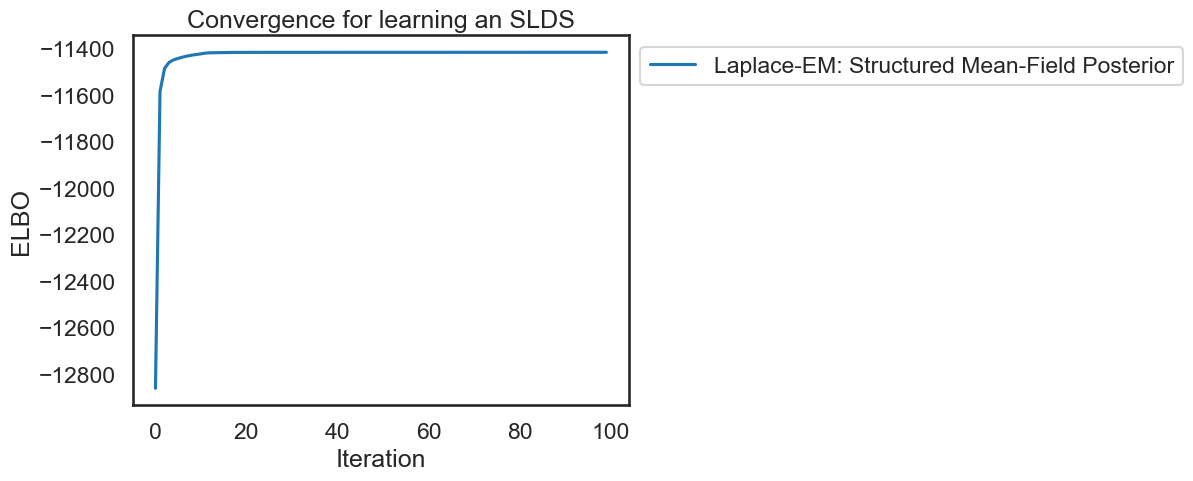

In [9]:
# Plot the ELBOs
plt.plot(q_lem_elbos, label="Laplace-EM: Structured Mean-Field Posterior")
plt.xlabel("Iteration")
plt.ylabel("ELBO")
plt.legend(bbox_to_anchor=(1.0,1.0))
plt.title("Convergence for learning an SLDS")
plt.show()

### 3.2 Exercise: The Evidence Lower Bound (ELBO)
In the SLDS model (and even in the LDS case with non-Gaussian observations), we can't optimize the log-likelihood directly. Instead, we optimize a lower bound on the log likelihood called the Evidence Lower Bound (ELBO). 

We denote the parameters of the model as $\Theta$, which are considered fixed for the purposes of this exercise. Concretely, we need to find a lower bound on $\log(P(Y \mid \Theta))$ where $Y=[y_1,\ldots,y_T]$. Can you use Jensen's inequality to derive a lower bound on this likelihood?

## 4. Visualize True and Inferred Latent States
Below, we compare how well the fitting algorithm recovers the discrete latent states. We then inspect the true vs. inferred continuous latent states.

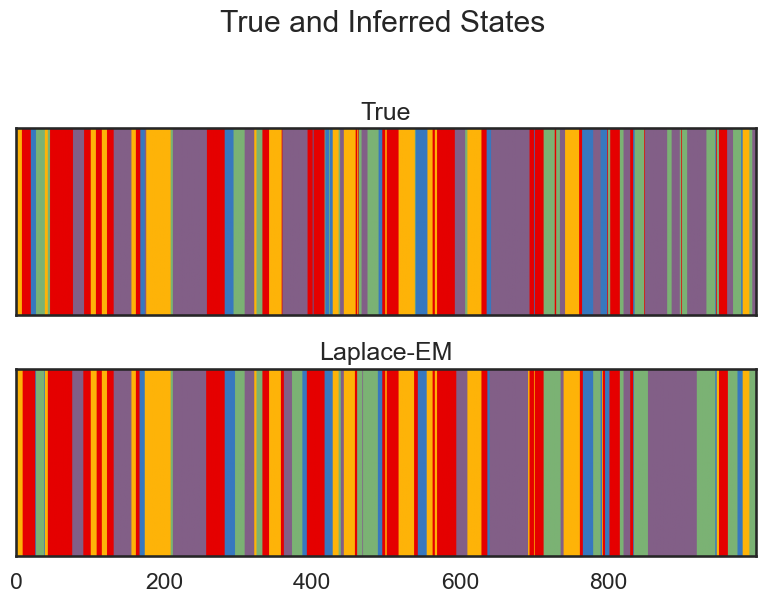

In [10]:
# Plot the true and inferred states
titles = ["True", "Laplace-EM"]
states_list = [states_z, q_lem_z]
fig, axs = plt.subplots(2,1, figsize=(8,6))
for (i, ax, states) in zip(range(len(axs)), axs, states_list):
    ax.imshow(states[None,:], aspect="auto", cmap=cmap_limited)
    ax.set_yticks([])
    ax.set_title(titles[i])
    if i < (len(axs) - 1):
        ax.set_xticks([])

plt.suptitle("True and Inferred States", va="baseline")
plt.tight_layout()

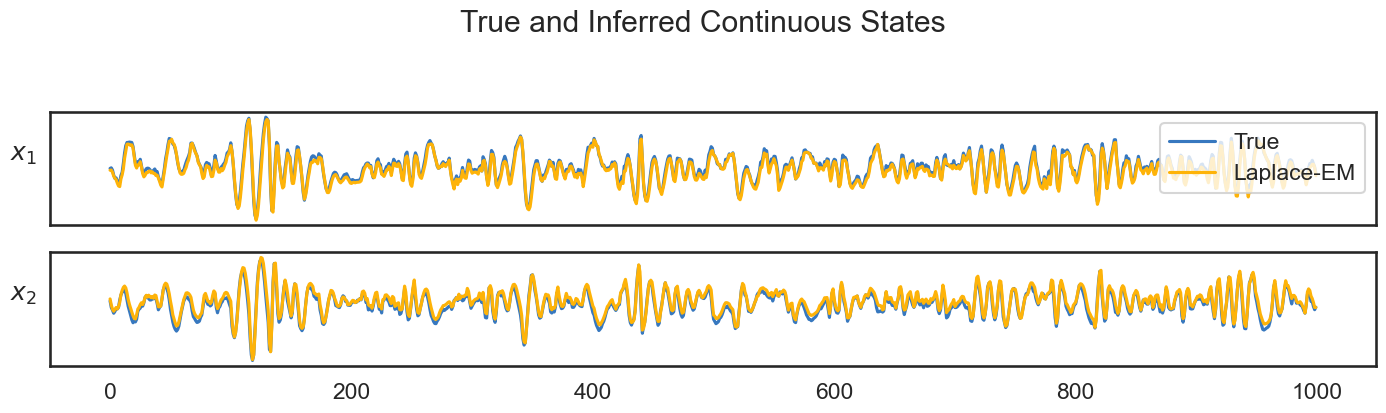

In [11]:
title_str = ["$x_1$", "$x_2$"]
fig, axs = plt.subplots(2,1, figsize=(14,4))
for (d, ax) in enumerate(axs):
    ax.plot(states_x[:,d] + 4 * d, '-', color=colors[0], label="True" if d==0 else None)
    ax.plot(q_lem_x[:,d] + 4 * d, '-', color=colors[2], label="Laplace-EM" if d==0 else None)
    ax.set_yticks([])
    ax.set_title(title_str[d], loc="left", y=0.5, x=-0.03)
axs[0].set_xticks([])
axs[0].legend(loc="upper right")

plt.suptitle("True and Inferred Continuous States", va="bottom")
plt.tight_layout()

### 4.1 Exercise: Fitting with fewer datapoints
From the above plots, it seems we were able to match the discrete states quite well using our learned model. Try reducing the number of time-bins used for fitting from 1000 to 500 or 100. At what point do we begin to fit badly?

## 5. Inference on unseen data
After learning a model from data, a common use-case is to compute the distribution over latent states given some new observations. For example, in the case of a simple LDS, we could use the Kalman Smoother to estimate the latent state trajectory given a set of observations. 

In the case of an SLDS (or Recurrent SLDS), the posterior over latent states can't be computed exactly. Instead, we need to live with a variational approximation to the true posterior. Dynamax allows us to compute this approximation using the `SLDS.approximate_posterior()` method. 

In the below example, we generate some new data from the true model. We then use the `approximate_posterior()` function to estimate the continuous and discrete states. 

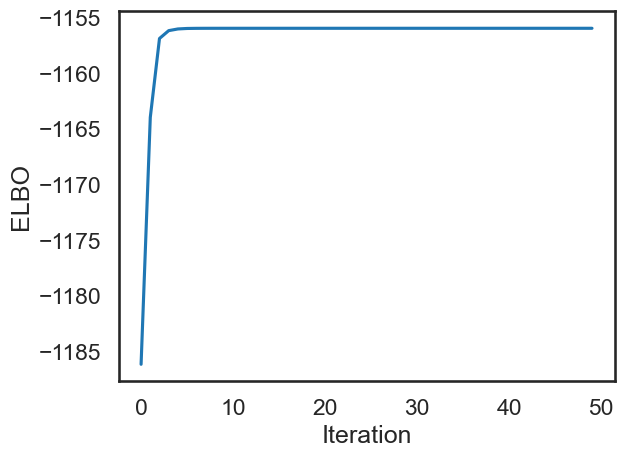

In [12]:
# Generate data which was not used for fitting
time_bins = 100
key, k_sample = jr.split(key)
data_z, data_x, data = true_slds.sample(true_params, k_sample, time_bins)

# Compute the approximate posterior over latent and continuous
# states for the new data under the current model parameters.
posterior, elbos = slds.approximate_posterior(params, data, num_iters=50)

# Verify that the ELBO increases during fitting. We don't expect a substantial increase:
# we are updating the estimate of the latent states but we are not changing model params.
plt.plot(elbos)
plt.xlabel("Iteration")
plt.ylabel("ELBO")
plt.show()

**Estimating Latent States**  
  
`posterior` is now a `PosteriorSLDS` object. Using this object, we can estimate the continuous and discrete states just like we did after calling `fit_em`.

In the below cell, we get the estimated continuous states as follows:
```python
posterior = jax.tree_util.tree_map(lambda a: a[0], posterior)
posterior_x = posterior.continuous.smoothed_means
```
These lines use the `continuous.smoothed_means` field of the posterior object. `approximate_posterior` returns the posterior with a leading batch axis, where each entry corresponds to a single trial of data. Since we have only passed in a single trial the batch will have length 1, and we take the first entry.

We then permute the discrete states to best match the ground truth. This is for aesthetic purposes when plotting. The following lines compute the best permutation which matches the predicted states (`most_likely`) to the ground truth discrete states (`data_z`). We then relabel the predicted states accordingly:
```python

most_likely = slds.most_likely_states(params, data, posterior)
perm = find_permutation(most_likely, data_z)
z_est = perm[most_likely]

```


In [13]:
# Get the posterior mean of the continuous states
posterior = jax.tree_util.tree_map(lambda a: a[0], posterior)   # one trial: take the first entry
posterior_x = posterior.continuous.smoothed_means

# Find the permutation that matches the true and inferred states
most_likely = slds.most_likely_states(params, data, posterior)
perm = find_permutation(most_likely, data_z)
z_est = perm[most_likely]

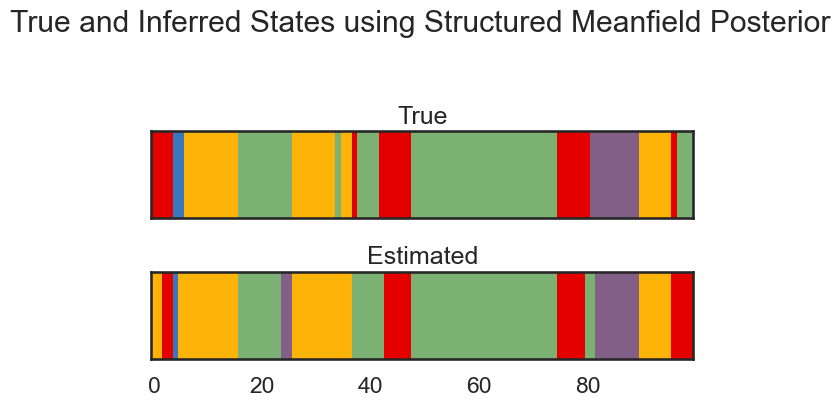

In [14]:
# Plot the true and inferred states
titles = ["True", "Estimated"]
states_list = [data_z, z_est]
fig, axs = plt.subplots(2,1, figsize=(6,4))
for (i, ax, states) in zip(range(len(axs)), axs, states_list):
    ax.imshow(states[None,:], aspect="auto", cmap=cmap_limited)
    ax.set_yticks([])
    ax.set_title(titles[i])
    if i < (len(axs) - 1):
        ax.set_xticks([])

plt.suptitle("True and Inferred States using Structured Meanfield Posterior", va="baseline")
plt.tight_layout()

In [15]:
x_est = posterior.continuous.smoothed_means

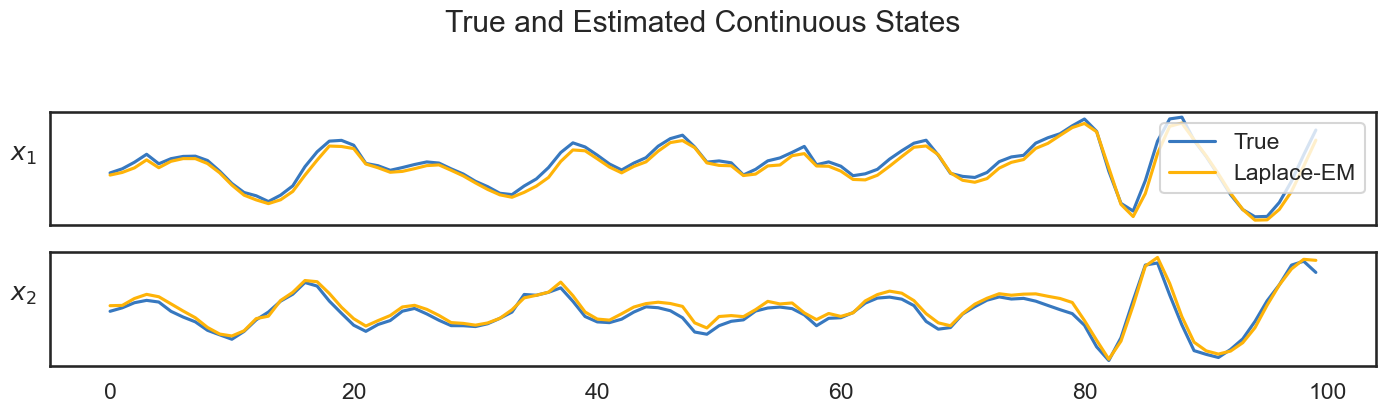

In [16]:
title_str = ["$x_1$", "$x_2$"]
fig, axs = plt.subplots(2,1, figsize=(14,4))
for (d, ax) in enumerate(axs):
    ax.plot(data_x[:,d] + 4 * d, '-', color=colors[0], label="True" if d==0 else None)
    ax.plot(x_est[:,d] + 4 * d, '-', color=colors[2], label="Laplace-EM" if d==0 else None)
    ax.set_yticks([])
    ax.set_title(title_str[d], loc="left", y=0.5, x=-0.03)
axs[0].set_xticks([])
axs[0].legend(loc="upper right")

plt.suptitle("True and Estimated Continuous States", va="bottom")
plt.tight_layout()